In [68]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt 
import seaborn as sns
from pathlib import Path 

sns.set_theme(style="whitegrid")

PASTA_DADOS = Path("data")
PASTA_FIGURAS = Path("figures")

PASTA_FIGURAS.mkdir(exist_ok=True)

df = pd.read_csv(
    r"C:\Users\Vaio\OneDrive\Documentos\detector_fraudes\creditcard.csv"
)

print("Base importada com sucesso!")
print("Dimensões:", df.shape)
display(df.head())

Base importada com sucesso!
Dimensões: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [69]:
df.info()

display(df.describe().T)

ausentes = df.isnull().sum()
print("Total de valores ausentes:", ausentes.sum())
display(ausentes[ausentes > 0])
print("Linhas duplicadas:", df.duplicated().sum())

print(df["Class"].value_counts(dropna=False))

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


Total de valores ausentes: 0


Series([], dtype: int64)

Linhas duplicadas: 1081
Class
0    284315
1       492
Name: count, dtype: int64


In [70]:
linhas_originais = len(df)
duplicatas_originais = int(df.duplicated().sum())
ausentes_originais = int(df.isna().sum().sum())

print(df.dtypes.value_counts())
print("Valores negativos em Amount:",
    (df["Amount"] < 0).sum())

print("Classes ausentes:", df["Class"].isna().sum())

df = df.dropna(subset=["Class"]).copy()

df = df[df["Class"].isin([0, 1])].copy()

duplicatas_restantes = int(df.duplicated().sum())

print("Linhas originais:", linhas_originais)
print("Duplicatas inicialmente encontradas:", duplicatas_originais)
print("Duplicatas após validar a classe:", duplicatas_restantes)
print("Ausentes inicialmente", ausentes_originais)
print("Dimensões após validação:", df.shape)

float64    30
int64       1
Name: count, dtype: int64
Valores negativos em Amount: 0
Classes ausentes: 0
Linhas originais: 284807
Duplicatas inicialmente encontradas: 1081
Duplicatas após validar a classe: 1081
Ausentes inicialmente 0
Dimensões após validação: (284807, 31)


In [71]:
df_tratado = df.drop_duplicates().copy()

print("Linhas após tratamento:", len(df_tratado))
print("duplicatas_restantes:", df_tratado.duplicated().sum())
print("Valores ausentes restantes:", df_tratado.isna().sum().sum())


df_tratado["Hora_aproximada"] = (
    (df_tratado["Time"] // 3600) % 24
).astype(int)

df_tratado["Tipo"] = df_tratado["Class"].map({
    0: "Legítima",
    1: "Fraude"
})

display(df_tratado.head())

Linhas após tratamento: 283726
duplicatas_restantes: 0
Valores ausentes restantes: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Class,Hora_aproximada,Tipo
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,0,Legítima
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,0,Legítima
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,0,Legítima
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,0,Legítima
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,0,Legítima


Tipo
Legítima    283253
Fraude         473
Name: count, dtype: int64


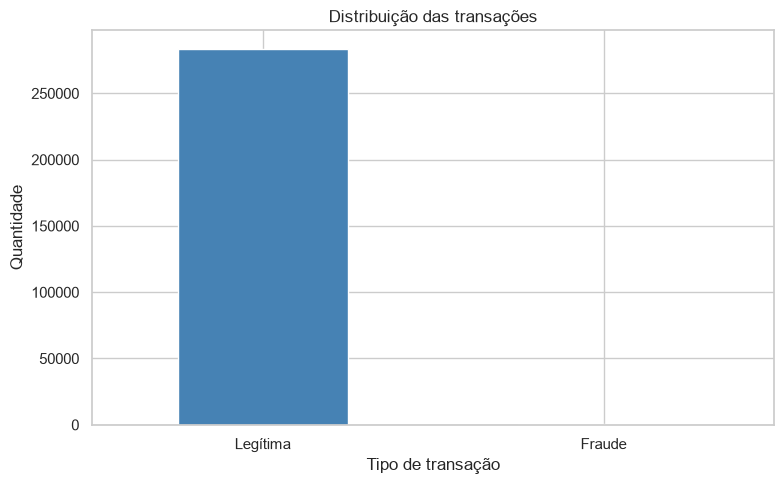

Percentual de fraudes: 0.1667 %


In [72]:
contagem = df_tratado["Tipo"].value_counts()

print(contagem)

contagem.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "tomato"]
)

plt.title("Distribuição das transações")
plt.xlabel("Tipo de transação")
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/distribuicao_classes.png", dpi=150)
plt.show()

print(
    "Percentual de fraudes:",
    round((df_tratado["Class"].mean() * 100), 4), "%"
)

,count,mean,median,std,min,max
Tipo,,,,,,
Fraude,473,123.871860,9.82,260.211041,0.0,2125.87
Legítima,283253,88.413575,22.00,250.379023,0.0,25691.16


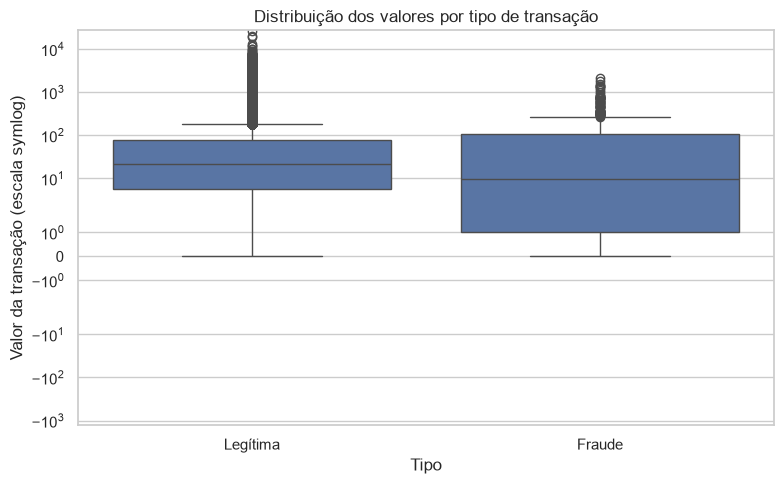

In [73]:
display(
    df_tratado.groupby("Tipo")["Amount"].agg(
        ["count", "mean", "median", "std", "min", "max"]
    )
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_tratado, 
    x="Tipo", 
    y="Amount"
)

plt.yscale("symlog")
plt.title("Distribuição dos valores por tipo de transação")
plt.xlabel("Tipo")
plt.ylabel("Valor da transação (escala symlog)")
plt.tight_layout()
plt.savefig("figures/valores_transacoes.png", dpi=150)
plt.show()

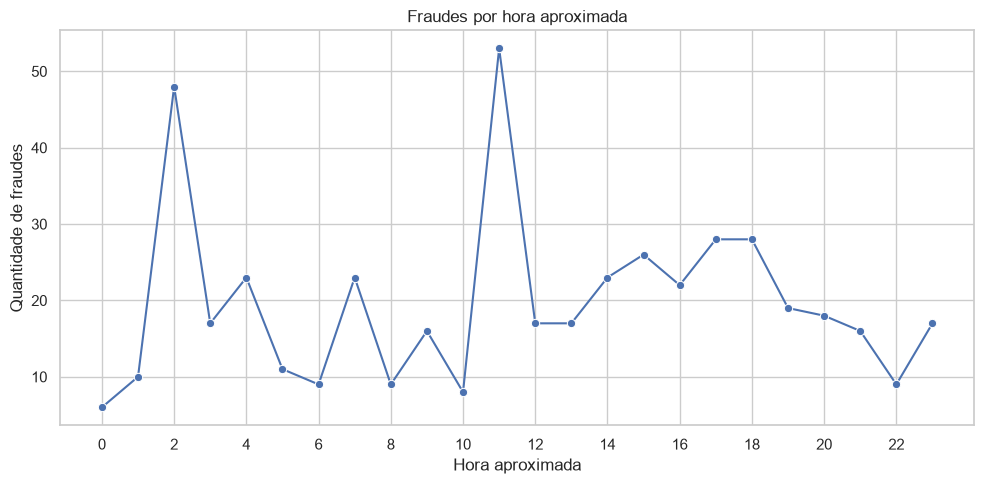

In [74]:
fraudes_por_hora = (
    df_tratado[df_tratado["Class"] == 1]
    .groupby("Hora_aproximada")
    .size()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=fraudes_por_hora.index, 
    y=fraudes_por_hora.values,
    marker="o"
)

plt.title("Fraudes por hora aproximada")
plt.xlabel("Hora aproximada")
plt.ylabel("Quantidade de fraudes")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig("figures/fraudes_tempo.png", dpi=150)
plt.show()

In [75]:
estatisticas = df_tratado.groupby("Tipo")["Amount"].agg(
    Quantidade="count",
    Media="mean",
    Mediana="median",
    Desvio_padrao="std",
    Minimo="min",
    Maximo="max",
)

display(estatisticas.round(2))

,Quantidade,Media,Mediana,Desvio_padrao,Minimo,Maximo
Tipo,,,,,,
Fraude,473,123.87,9.82,260.21,0.0,2125.87
Legítima,283253,88.41,22.00,250.38,0.0,25691.16


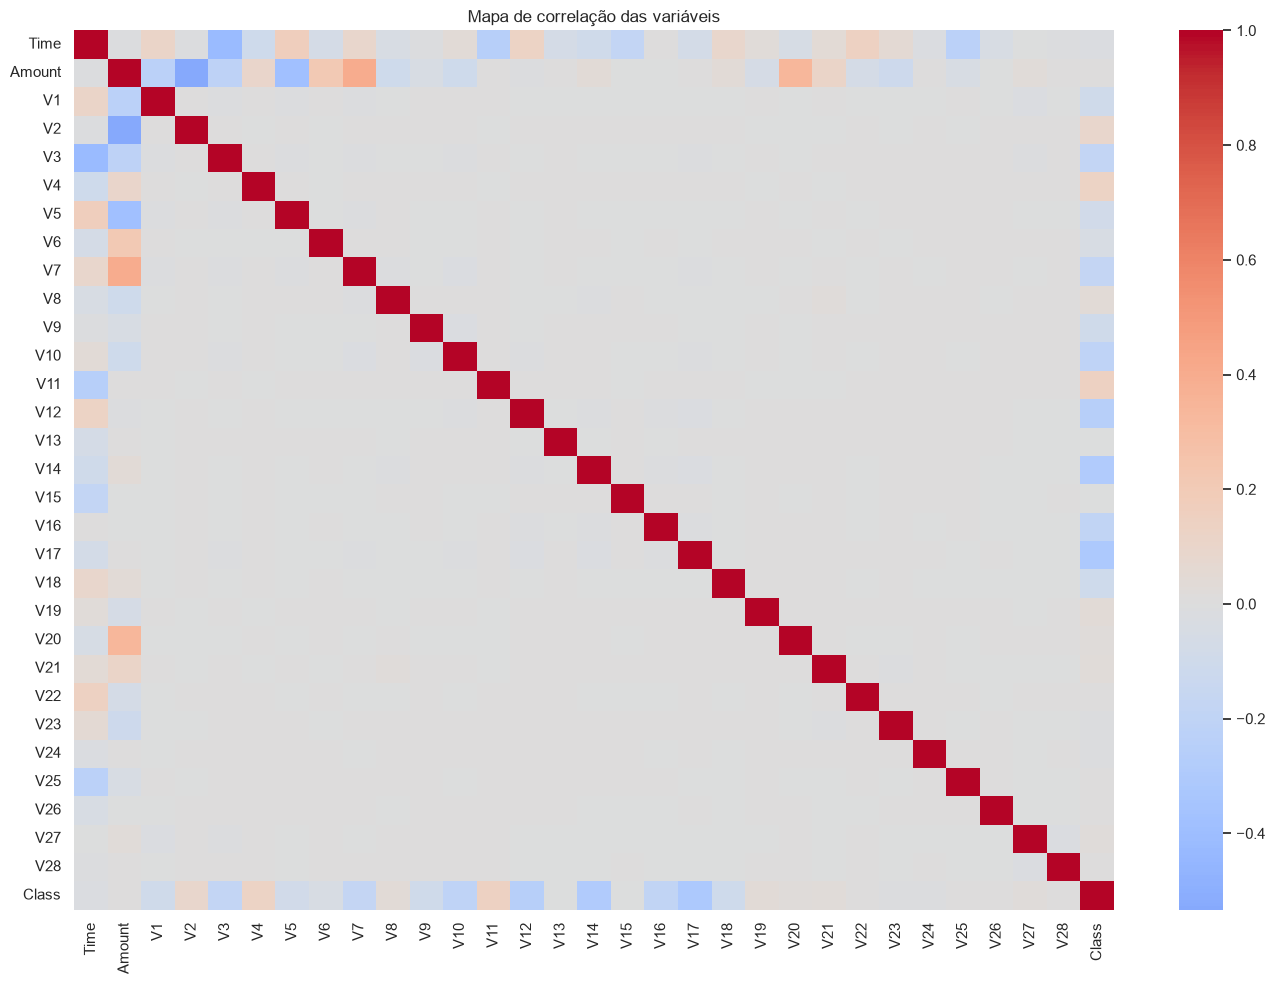

Correlação com a classe:


V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
V3    -0.182322
V7    -0.172347
V11    0.149067
V4     0.129326
V18   -0.105340
Name: Class, dtype: float64

In [76]:
colunas = ["Time", "Amount"] + [
    f"V{i}" for i in range (1, 29)
] + ["Class"]

correlacao = df_tratado[colunas].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlacao,
    cmap="coolwarm",
    center=0,
    xticklabels=True,
    yticklabels=True
)

plt.title("Mapa de correlação das variáveis")
plt.tight_layout()
plt.savefig("figures/mapa_correlacao.png", dpi=150)
plt.show()

print("Correlação com a classe:")
display(
    correlacao["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
    .head(10)
)